In [34]:
import pandas as pd
import matplotlib.pyplot as plt

In [35]:
df=pd.read_csv("customer_churn_data.csv")

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        10 non-null     int64  
 1   Gender    9 non-null      str    
 2   Age       9 non-null      float64
 3   Contract  9 non-null      str    
 4   Bill      10 non-null     int64  
 5   Churn     10 non-null     int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 612.0 bytes


In [37]:
df

,ID,Gender,Age,Contract,Bill,Churn
0,101,Male,25.0,Monthly,50,0
1,102,Female,45.0,Annual,100,1
2,103,Female,30.0,Monthly,45,0
3,104,Male,50.0,Annual,110,1
4,105,Female,22.0,Monthly,55,0
5,106,NaN,35.0,Monthly,60,0
6,107,Male,NaN,Annual,105,1
7,108,Female,60.0,NaN,95,0
8,109,Male,42.0,Two Year,120,1
9,110,Female,33.0,Monthly,65,0


In [38]:
#cleaning

df["Age"]=df["Age"].fillna(df["Age"].median())
df['Contract']=df['Contract'].fillna(df['Contract'].mode()[0])
df['Gender']=df['Gender'].fillna(df['Gender'].mode()[0])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        10 non-null     int64  
 1   Gender    10 non-null     str    
 2   Age       10 non-null     float64
 3   Contract  10 non-null     str    
 4   Bill      10 non-null     int64  
 5   Churn     10 non-null     int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 612.0 bytes


In [39]:
df

,ID,Gender,Age,Contract,Bill,Churn
0,101,Male,25.0,Monthly,50,0
1,102,Female,45.0,Annual,100,1
2,103,Female,30.0,Monthly,45,0
3,104,Male,50.0,Annual,110,1
4,105,Female,22.0,Monthly,55,0
5,106,Female,35.0,Monthly,60,0
6,107,Male,35.0,Annual,105,1
7,108,Female,60.0,Monthly,95,0
8,109,Male,42.0,Two Year,120,1
9,110,Female,33.0,Monthly,65,0


In [40]:
ageLabel=['Young','Adult','Senior']

df["AgeGroup"]=pd.cut(df["Age"],bins=3,labels=ageLabel)

df

,ID,Gender,Age,Contract,Bill,Churn,AgeGroup
0,101,Male,25.0,Monthly,50,0,Young
1,102,Female,45.0,Annual,100,1,Adult
2,103,Female,30.0,Monthly,45,0,Young
3,104,Male,50.0,Annual,110,1,Senior
4,105,Female,22.0,Monthly,55,0,Young
5,106,Female,35.0,Monthly,60,0,Adult
6,107,Male,35.0,Annual,105,1,Adult
7,108,Female,60.0,Monthly,95,0,Senior
8,109,Male,42.0,Two Year,120,1,Adult
9,110,Female,33.0,Monthly,65,0,Young


In [44]:
risk=(df['Contract']=='Monthly') & (df['Bill']>100)

df['HighRisk']=risk.astype(int)

df

,ID,Gender,Age,Contract,Bill,Churn,AgeGroup,HighRisk
0,101,Male,25.0,Monthly,50,0,Young,0
1,102,Female,45.0,Annual,100,1,Adult,0
2,103,Female,30.0,Monthly,45,0,Young,0
3,104,Male,50.0,Annual,110,1,Senior,0
4,105,Female,22.0,Monthly,55,0,Young,0
5,106,Female,35.0,Monthly,60,0,Adult,0
6,107,Male,35.0,Annual,105,1,Adult,0
7,108,Female,60.0,Monthly,95,0,Senior,0
8,109,Male,42.0,Two Year,120,1,Adult,0
9,110,Female,33.0,Monthly,65,0,Young,0


In [48]:
summary=df.groupby(['Contract','AgeGroup']).agg(
    CustomerCount=('ID','count'),
    MonthBill=('Bill','mean')
)

summary


CustomerCount  MonthBill
Contract AgeGroup                          
Annual   Adult                 2     102.50
         Senior                1     110.00
Monthly  Young                 4      53.75
         Adult                 1      60.00
         Senior                1      95.00
Two Year Adult                 1     120.00

In [ ]:
avGBills=df.groupby(['Contract','Churn'])['Bill'].mean()


Contract  Churn
Annual    1        105.000000
Monthly   0         61.666667
Two Year  1        120.000000
Name: Bill, dtype: float64

Text(0, 0.5, 'Avg monthly bill')

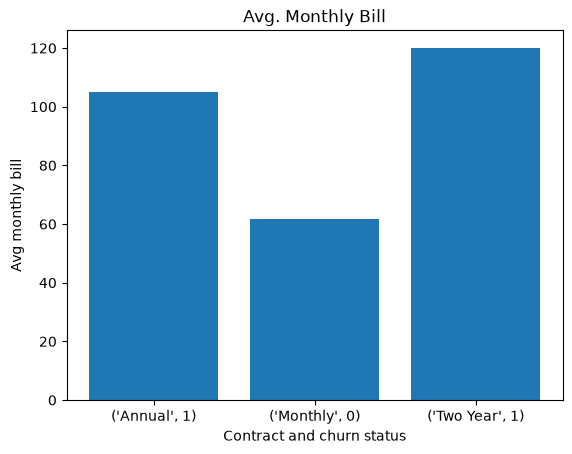

In [57]:
fig,ax=plt.subplots()

x_labels=[str(x) for x in avGBills.index]

y_values=avGBills.values
ax.bar(x_labels,y_values)

ax.set_title('Avg. Monthly Bill')
ax.set_xlabel('Contract and churn status')
ax.set_ylabel('Avg monthly bill')